<a href="https://colab.research.google.com/github/khaylatiara17/perpustakaan-sqlite/blob/main/Perpustakaan_SQLite_dan_Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sistem basis data perpustakaan

Saya menggunakan SQLite untuk mencatat siapa yang meminjam buku dan kapan buku itu kembali. Lalu saya memakai pandas dan Matplotlib untuk melihat jumlah pinjaman per anggota serta lama peminjaman yang sudah selesai.

Jalankan sel dari atas ke bawah melalui **Runtime → Run all**. Notebook membuat file `perpustakaan_latihan.sqlite3` di folder kerja sesi Colab. Semua nama, alamat email, buku, dan transaksi di bawah ini adalah data contoh.

## 1. Membuat tiga tabel di SQLite

Tabel `buku` menyimpan katalog dan tabel `anggota` menyimpan data peminjam. Pada tabel `peminjaman`, setiap baris menghubungkan satu anggota dengan satu buku. Saya mengaktifkan pemeriksaan *foreign key* agar setiap nomor anggota dan buku pada transaksi merujuk ke data yang terdaftar. Tanggal memakai format `YYYY-MM-DD`.

In [22]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator

koneksi = sqlite3.connect("perpustakaan_latihan.sqlite3")
koneksi.execute("PRAGMA foreign_keys = ON")

koneksi.executescript("""
    CREATE TABLE IF NOT EXISTS buku (
        id      INTEGER PRIMARY KEY,
        judul   TEXT NOT NULL,
        penulis TEXT NOT NULL,
        tahun   INTEGER NOT NULL CHECK (tahun > 0)
    );

    CREATE TABLE IF NOT EXISTS anggota (
        id    INTEGER PRIMARY KEY,
        nama  TEXT NOT NULL,
        email TEXT NOT NULL UNIQUE
    );

    CREATE TABLE IF NOT EXISTS peminjaman (
        id          INTEGER PRIMARY KEY,
        id_anggota  INTEGER NOT NULL,
        id_buku     INTEGER NOT NULL,
        tgl_pinjam  TEXT NOT NULL,
        tgl_kembali TEXT,
        FOREIGN KEY (id_anggota) REFERENCES anggota(id),
        FOREIGN KEY (id_buku) REFERENCES buku(id),
        CHECK (tgl_kembali IS NULL OR tgl_kembali >= tgl_pinjam)
    );
""")
print("Tabel buku, anggota, dan peminjaman siap digunakan.")

Tabel buku, anggota, dan peminjaman siap digunakan.


## 1a. Menambahkan lima buku dan tiga anggota

Saya memberi setiap buku dan anggota ID tetap. Jika sel dijalankan ulang, `ON CONFLICT(id) DO NOTHING` menjaga agar baris dengan ID yang sama tidak ditambahkan dua kali.

In [16]:
data_buku = [
    (1, "Dasar Basis Data", "Damar Wijaya", 2021),
    (2, "Langkah Pertama dengan Python", "Ratih Sasmita", 2022),
    (3, "Membaca Data dengan Grafik", "Nara Santoso", 2023),
    (4, "Algoritma dalam Keseharian", "Tari Mahendra", 2024),
    (5, "Merancang Aplikasi Sederhana", "Laras Utami", 2025),
]

data_anggota = [
    (1, "Alya Putri", "alya@example.com"),
    (2, "Bima Pratama", "bima@example.com"),
    (3, "Citra Dewi", "citra@example.com"),
]

with koneksi:
    koneksi.executemany("""
        INSERT INTO buku (id, judul, penulis, tahun)
        VALUES (?, ?, ?, ?) ON CONFLICT(id) DO NOTHING
    """, data_buku)
    koneksi.executemany("""
        INSERT INTO anggota (id, nama, email)
        VALUES (?, ?, ?) ON CONFLICT(id) DO NOTHING
    """, data_anggota)

display(pd.read_sql_query("SELECT * FROM buku ORDER BY id", koneksi, index_col="id"))
display(pd.read_sql_query("SELECT * FROM anggota ORDER BY id", koneksi, index_col="id"))

,judul,penulis,tahun
id,,,
1,Dasar Basis Data,Damar Wijaya,2021
2,Langkah Pertama dengan Python,Ratih Sasmita,2022
3,Membaca Data dengan Grafik,Nara Santoso,2023
4,Algoritma dalam Keseharian,Tari Mahendra,2024
5,Merancang Aplikasi Sederhana,Laras Utami,2025


,nama,email
id,,
1,Alya Putri,alya@example.com
2,Bima Pratama,bima@example.com
3,Citra Dewi,citra@example.com


## 1b. Mencatat empat transaksi peminjaman

Pada transaksi keempat, Alya masih meminjam buku *Algoritma dalam Keseharian*. Saya mengisi tanggal kembalinya dengan `None` di Python. SQLite menyimpan nilai itu sebagai `NULL`.

In [17]:
# Urutan nilai: ID transaksi, ID anggota, ID buku, tanggal pinjam, tanggal kembali.
data_peminjaman = [
    (1, 1, 1, "2026-11-02", "2026-11-06"),
    (2, 2, 2, "2026-11-03", "2026-11-09"),
    (3, 1, 3, "2026-11-05", "2026-11-13"),
    (4, 1, 4, "2026-11-14", None),
]

with koneksi:
    koneksi.executemany("""
        INSERT INTO peminjaman (id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
        VALUES (?, ?, ?, ?, ?) ON CONFLICT(id) DO NOTHING
    """, data_peminjaman)

jumlah_transaksi = koneksi.execute("SELECT COUNT(*) FROM peminjaman").fetchone()[0]
print(f"Jumlah transaksi tersimpan = {jumlah_transaksi}")

Jumlah transaksi tersimpan = 4


## 1c dan 2a. Menampilkan daftar peminjaman sebagai DataFrame

Dua operasi `JOIN` mengambil nama anggota dan judul buku untuk setiap transaksi. Fungsi `pd.read_sql_query()` langsung menyimpan hasilnya dalam DataFrame `df_peminjaman`. Karena kedua kolom tanggal dibaca sebagai tanggal, pandas menampilkan tanggal kembali yang kosong sebagai `NaT`.

In [18]:
sql_daftar = """
    SELECT p.id AS id_peminjaman,
           a.nama AS nama_anggota,
           b.judul AS judul_buku,
           p.tgl_pinjam,
           p.tgl_kembali
    FROM peminjaman AS p
    JOIN anggota AS a ON a.id = p.id_anggota
    JOIN buku AS b ON b.id = p.id_buku
    ORDER BY p.tgl_pinjam, p.id
"""

df_peminjaman = pd.read_sql_query(
    sql_daftar,
    koneksi,
    parse_dates=["tgl_pinjam", "tgl_kembali"],
)
display(df_peminjaman.set_index("id_peminjaman"))

,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
id_peminjaman,,,,
1,Alya Putri,Dasar Basis Data,2026-11-02,2026-11-06
2,Bima Pratama,Langkah Pertama dengan Python,2026-11-03,2026-11-09
3,Alya Putri,Membaca Data dengan Grafik,2026-11-05,2026-11-13
4,Alya Putri,Algoritma dalam Keseharian,2026-11-14,NaT


## 1d. Menghitung total buku yang dipinjam setiap anggota

Satu transaksi mewakili peminjaman satu buku. `GROUP BY` mengelompokkan transaksi per anggota. `LEFT JOIN` menyertakan anggota yang belum pernah meminjam. Pada anggota seperti Citra, `COUNT(p.id)` menghasilkan nol karena tidak ada ID transaksi yang terisi. Pinjaman yang masih berjalan tetap masuk ke jumlah buku.

In [19]:
sql_total = """
    SELECT a.id AS id_anggota,
           a.nama AS nama_anggota,
           COUNT(p.id) AS jumlah_buku
    FROM anggota AS a
    LEFT JOIN peminjaman AS p ON p.id_anggota = a.id
    GROUP BY a.id, a.nama
    ORDER BY jumlah_buku DESC, a.nama, a.id
"""

df_total = pd.read_sql_query(sql_total, koneksi)
display(df_total.set_index("id_anggota"))

,nama_anggota,jumlah_buku
id_anggota,,
1,Alya Putri,3
2,Bima Pratama,1
3,Citra Dewi,0


## 2b. Menghitung durasi peminjaman

Saya menghitung selisih hari kalender antara tanggal kembali dan tanggal pinjam. Contohnya, dari 2 November sampai 6 November durasinya empat hari. Untuk transaksi yang masih berjalan, durasi akhir tetap kosong. Rata-rata dihitung dari transaksi yang memiliki tanggal kembali.

In [20]:
df_durasi = df_peminjaman.copy()
selisih = df_durasi["tgl_kembali"] - df_durasi["tgl_pinjam"]
df_durasi["durasi_hari"] = selisih.dt.days.astype("Int64")
df_durasi["status"] = df_durasi["tgl_kembali"].isna().map({
    True: "Masih dipinjam",
    False: "Sudah kembali",
})

kolom_hasil = ["nama_anggota", "judul_buku", "status", "durasi_hari"]
display(df_durasi.set_index("id_peminjaman")[kolom_hasil])

durasi_selesai = df_durasi["durasi_hari"].dropna()
jumlah_aktif = df_durasi["tgl_kembali"].isna().sum()
print(f"Sudah kembali = {len(durasi_selesai)} transaksi")
print(f"Masih dipinjam = {jumlah_aktif} transaksi")
if not durasi_selesai.empty:
    print(f"Rata-rata durasi peminjaman selesai = {durasi_selesai.mean():g} hari")

,nama_anggota,judul_buku,status,durasi_hari
id_peminjaman,,,,
1,Alya Putri,Dasar Basis Data,Sudah kembali,4
2,Bima Pratama,Langkah Pertama dengan Python,Sudah kembali,6
3,Alya Putri,Membaca Data dengan Grafik,Sudah kembali,8
4,Alya Putri,Algoritma dalam Keseharian,Masih dipinjam,<NA>


Sudah kembali = 3 transaksi
Masih dipinjam = 1 transaksi
Rata-rata durasi peminjaman selesai = 6 hari


## 2c. Membandingkan jumlah peminjaman per anggota

Saya memakai diagram batang karena yang ingin dibandingkan adalah jumlah buku pada tiap anggota. Panjang batang menunjukkan jumlah transaksi. Angka di ujung batang membantu membaca nilai nol.

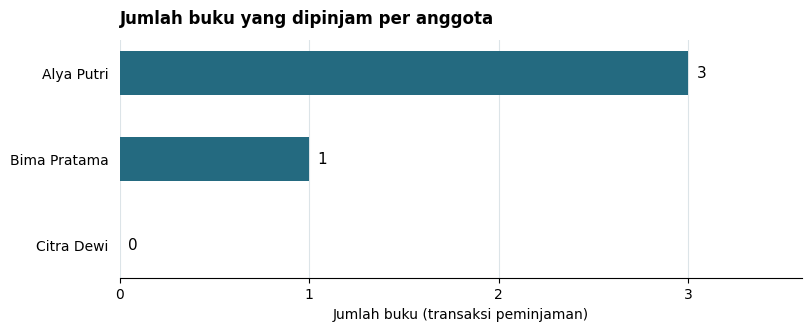

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
batang = ax.barh(
    df_total["nama_anggota"], df_total["jumlah_buku"],
    height=0.52, color="#246A80",
)
ax.invert_yaxis()
ax.bar_label(batang, padding=6, fontsize=11)
ax.set_title("Jumlah buku yang dipinjam per anggota", loc="left", pad=12, weight="bold")
ax.set_xlabel("Jumlah buku (transaksi peminjaman)")
ax.set_xlim(0, max(1, df_total["jumlah_buku"].max()) + 0.6)
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
ax.grid(axis="x", color="#DCE4E8", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, pad=8)
plt.show()

## Kesimpulan

Dalam data contoh ini, Alya meminjam tiga buku, Bima satu buku, dan Citra belum pernah meminjam. Tiga transaksi yang sudah selesai berlangsung selama 4, 6, dan 8 hari. Rata-ratanya adalah 6 hari. Satu buku masih dipinjam Alya. Transaksi tersebut menambah total pinjaman Alya, sedangkan durasi akhirnya baru bisa dihitung setelah buku dikembalikan.